# Improvement Compared to V1
- processing it as greyscale. 
- model uses 1 channel. 
- reduces complexity to train. 
cons: 
- transfer learning need 3 channels

In [5]:
import os 
import tensorflow as tf 
from tensorflow.keras import layers, models, optimizers
from dotenv import load_dotenv


In [ ]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
train_data_dir = os.path.join(dataset_path, "data", "train")
test_data_dir = os.path.join(dataset_path, "data", "test")
val_data_dir = os.path.join(dataset_path, "data", "val")

In [11]:


types = ["normal", "pneumonia", "tuberculosis"]
# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical', # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
)

Found 20450 files belonging to 3 classes.
Found 2569 files belonging to 3 classes.
Found 2534 files belonging to 3 classes.


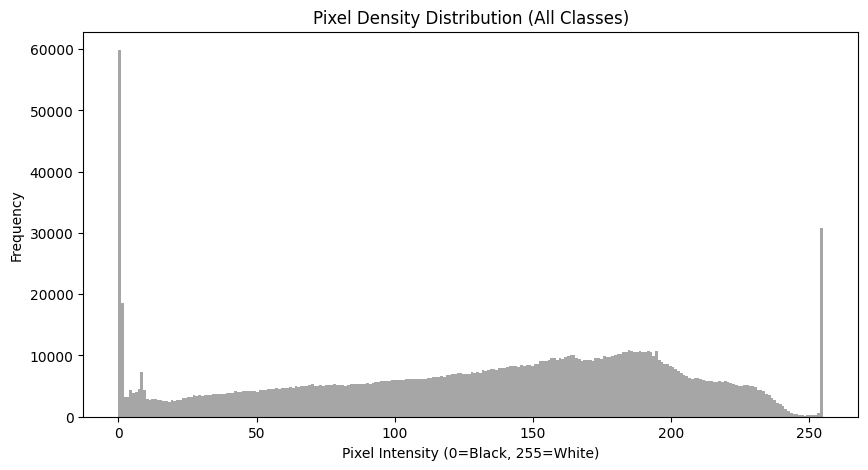

2026-02-15 04:21:23.486555: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Take one batch (e.g., 32 images)
for images, labels in train_ds.take(1):
    # Flatten all pixels in the batch into a 1D array
    pixels = images.numpy().flatten()
    
    plt.figure(figsize=(10, 5))
    plt.hist(pixels, bins=256, color='gray', alpha=0.7)
    plt.title('Pixel Density Distribution (All Classes)')
    plt.xlabel('Pixel Intensity (0=Black, 255=White)')
    plt.ylabel('Frequency')
    plt.show()

2026-02-15 04:21:31.595809: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


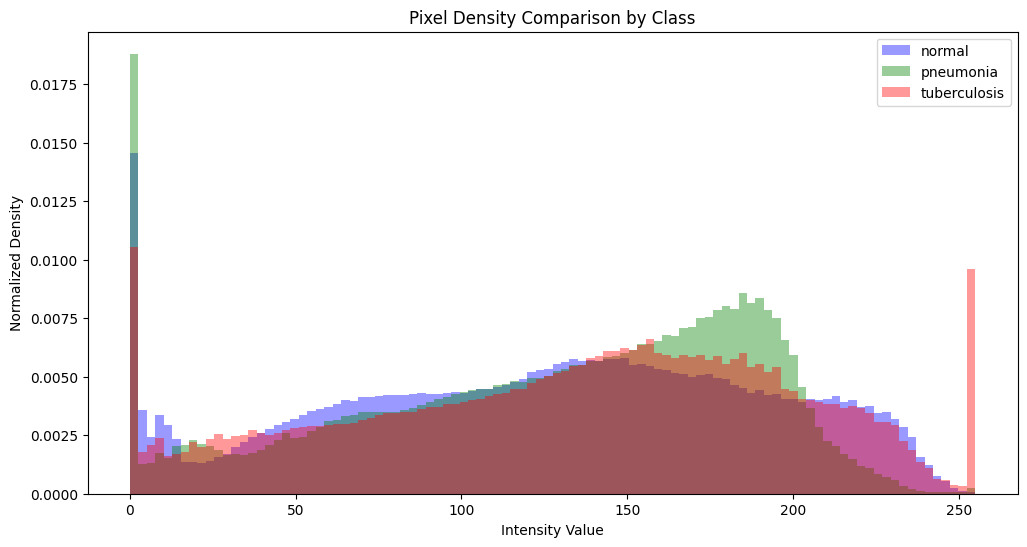

In [ ]:
def plot_class_histograms(dataset, class_names):
    plt.figure(figsize=(12, 6))
    
    # Store pixels for each class
    class_pixels = {name: [] for name in class_names}
    
    # Analyze 5 batches for a good sample size
    for images, labels in dataset.take(5):
        images = images.numpy()
        labels = np.argmax(labels.numpy(), axis=1)
        
        for i in range(len(images)):
            cls_name = class_names[labels[i]]
            # Add flattened pixels of this specific image
            class_pixels[cls_name].extend(images[i].flatten())

    # Plotting
    colors = ['blue', 'green', 'red']
    for i, name in enumerate(class_names):
        plt.hist(class_pixels[name], bins=100, alpha=0.4, 
                 label=name, color=colors[i], density=True)

    plt.title('Pixel Density Comparison by Class')
    plt.xlabel('Intensity Value')
    plt.ylabel('Normalized Density')
    plt.legend()
    plt.show()

# Usage
plot_class_histograms(train_ds, train_ds.class_names)

In [ ]:
# 1. Refined Augmentation
# We keep rotations small to avoid changing the anatomical orientation of the lungs.
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05), 
    layers.RandomZoom(0.15), # Increased slightly to help with varying lung sizes
    layers.RandomContrast(0.1), # Important for X-ray visibility differences
])

# 2. Multi-Class Diagnostic Model
model = models.Sequential([
    # Input: Standardizing to 3 channels is often safer if using pre-trained weights later, 
    # but stick to '1' if your dataset is strictly grayscale.
    layers.Input(shape=(224, 224, 1)), 
    
    data_augmentation,
    layers.Rescaling(1./255),
    
    # Block 1 - Early edge detection
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 2 - Textures and patterns (Cloudiness vs. Nodules)
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 3 - Complex features
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 4 - High-level semantic features (Specific to TB and Pneumonia localization)
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 5 - Deep pattern extraction
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    
    layers.GlobalAveragePooling2D(), 
    
    # Dense Head - Multi-stage narrowing
    # Two dense layers help the model better differentiate between the three labels
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4), 
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    
    # Output: 3 neurons for [Normal, Pneumonia, TB]
    layers.Dense(3, activation='softmax')
])

In [ ]:
# 3. Compile with a LOWER Learning Rate
# Default Adam is 0.001. Dropping to 0.0001 prevents the "Loss Explosion"
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
640/640 ━━━━━━━━━━━━━━━━━━━━ 534s 833ms/step - accuracy: 0.6948 - loss: 0.6353 - val_accuracy: 0.5126 - val_loss: 2.2955
Epoch 2/5
640/640 ━━━━━━━━━━━━━━━━━━━━ 505s 789ms/step - accuracy: 0.7456 - loss: 0.5057 - val_accuracy: 0.4653 - val_loss: 3.7413
Epoch 3/5
640/640 ━━━━━━━━━━━━━━━━━━━━ 504s 787ms/step - accuracy: 0.7533 - loss: 0.4899 - val_accuracy: 0.7616 - val_loss: 0.5321
Epoch 4/5
640/640 ━━━━━━━━━━━━━━━━━━━━ 498s 779ms/step - accuracy: 0.7625 - loss: 0.4558 - val_accuracy: 0.7644 - val_loss: 0.4822
Epoch 5/5
640/640 ━━━━━━━━━━━━━━━━━━━━ 508s 794ms/step - accuracy: 0.7645 - loss: 0.4454 - val_accuracy: 0.7616 - val_loss: 0.4990


In [ ]:
# Save the model
model.save('CXC02.keras')
print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 180ms/step - accuracy: 0.7633 - loss: 0.5100
Test Loss: 0.5100356340408325
Test Accuracy: 76.33%


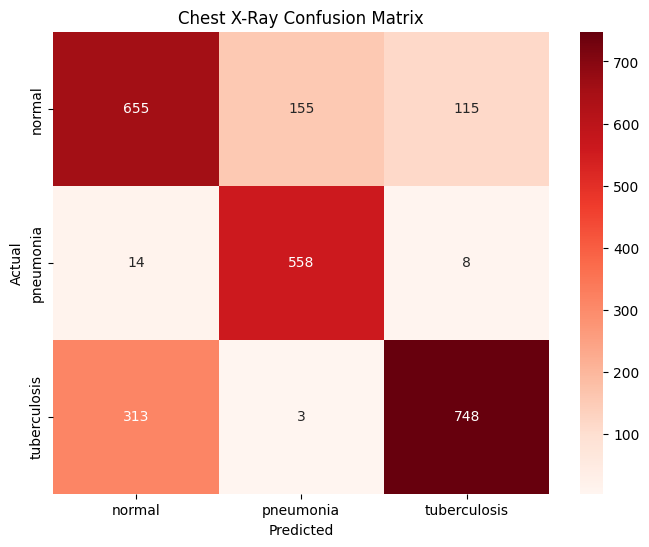

              precision    recall  f1-score   support

      normal       0.67      0.71      0.69       925
   pneumonia       0.78      0.96      0.86       580
tuberculosis       0.86      0.70      0.77      1064

    accuracy                           0.76      2569
   macro avg       0.77      0.79      0.77      2569
weighted avg       0.77      0.76      0.76      2569



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Chest X-Ray Confusion Matrix')
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf

# 1. Load the Test Dataset (Make sure shuffle=False for evaluation!)
test_ds = tf.keras.utils.image_dataset_from_directory(
    '../../../data/test',
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical',
    shuffle=False  # CRITICAL: Do not shuffle for the Confusion Matrix
)

# 2. Load your saved model
model = tf.keras.models.load_model('CXC02.keras')

# 3. Get Predictions
print("Evaluating model...")
# This method is quiet and won't trigger the "End of Sequence" warning
predictions = model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

# 4. Get True Labels
# We extract labels from the dataset manually
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

# 5. Generate metrics
class_names = test_ds.class_names
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# 6. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix: Actual vs Predicted')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

Found 2569 files belonging to 3 classes.
Evaluating model...


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'None' of layer 'conv2d_10' is incompatible with the layer: expected axis -1 of input shape to have value 1, but received input with shape (32, 224, 224, 3)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(32, 224, 224, 3), dtype=float32)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [ ]:
model = tf.keras.models.load_model('CXC02.keras')
print(model.input_shape)
# Verify the architecture
model.summary()

(None, 224, 224, 1)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,267,211 (4.83 MB)

 Trainable params: 422,083 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 844,168 (3.22 MB)

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

def predict_single_image(img_path, model):
    # 1. Load and resize the image
    img = image.load_img(img_path, target_size=(224, 224), color_mode='grayscale')
    
    # 2. Convert to array and add batch dimension
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) 
    
    # 3. Predict
    predictions = model.predict(img_array)
    
    # 4. Get class names (assuming standard order: Normal, Pneumonia, TB)
    # Note: These usually follow alphabetical order of your folders
    class_names = ['Normal', 'Pneumonia', 'Tuberculosis']
    result = class_names[np.argmax(predictions)]
    confidence = np.max(predictions) * 100
    
    return result, confidence

# Usage:
label, score = predict_single_image('../../../data/test/normal/normal-921.jpg', model)
print(f"Prediction: {label} ({score:.2f}%)")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
Prediction: Normal (80.90%)
